# ms01 阶段 1–3：去异常骨架、插值、平滑

只读**开发组**，只看数据本身的分布（骨架长度、缺口、抖动）。唯一用到行为标记的地方是阶段 3 的“快行为位置”，
只用来判断平滑会不会削掉速度峰，不用来调阈值让分类好看。

3 点骨架 = 嘴、胸鳍、尾（没有尾鳍），所以论文的“头–胸鳍 / 胸鳍–尾”对应这里的 嘴–胸鳍、胸鳍–尾。
输入是审阅包里**未插值**的 `nodes3d`（不是 `nodes3d_filled`），已经按账本换回身份，审阅判为不可用的帧是 NaN 且**绝不填、绝不跨过**。

## 阶段 1：去异常骨架

对每个视频、每条鱼，算 嘴–胸鳍 和 胸鳍–尾 的长度，除以该鱼该视频的中位数得到比值 r（所以雌雄体长差、不同视频的差异都被消掉）。
r 的直方图：主峰是正常，远离主峰的长尾是追踪错误，下限一侧是头和胸鳍几乎重合。阈值 = 主峰和长尾之间的谷，写成 `k × 中位数`。
`suggest_k` 给出一个建议（密度降到主峰 1% 的第一个 bin），**图要自己看**；下面 `K_*_OVERRIDE` 可手动改。
不用任何标记。

**读图结论（K_1，三天）**：主峰右侧不是干净的“谷”，而是一段平滑的肩部（r 约 1.2–1.4，密度逐级下降），再往后是稀疏长尾；
左侧同理。所以阈值落在肩部，位置有一定任意性。S1_02 显示阈值在 1.2→1.4 之间移动，去掉的帧只从约 0.2% 降到 0.05%，影响很小；
S1_03 抽样看，被去掉的骨架确实是断裂/重叠的。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*keyword-only.*")
warnings.filterwarnings("ignore", message=".*keyword-only.*")


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms01_clean_interpolate_smooth.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
DEV = M.trials("dev")
print("dev trials:", DEV)
TR = {e: M.load_trial(e) for e in DEV}
RATIO = {k: {} for k in ("head_pec", "pec_tail")}
for e, t in TR.items():
    L = M.skeleton_lengths(t["named"])
    for k in RATIO:
        RATIO[k][e] = L[k] / np.nanmedian(L[k], axis=0)

K_LO, K_HI = {}, {}
for k in RATIO:
    pooled = np.concatenate([r.ravel() for r in RATIO[k].values()])
    K_LO[k], K_HI[k] = M.suggest_k(pooled)
print("suggested k_lo:", K_LO)
print("suggested k_hi:", K_HI)

dev trials: ['20251225_K_1_1_FCMC', '20251225_K_1_2_FCMC', '20251225_K_1_3_FCMC']


suggested k_lo: {'head_pec': 0.7000000000000001, 'pec_tail': 0.65}
suggested k_hi: {'head_pec': 1.25, 'pec_tail': 1.2000000000000002}


used k_lo: {'head_pec': 0.7000000000000001, 'pec_tail': 0.65}  k_hi: {'head_pec': 1.25, 'pec_tail': 1.2000000000000002}


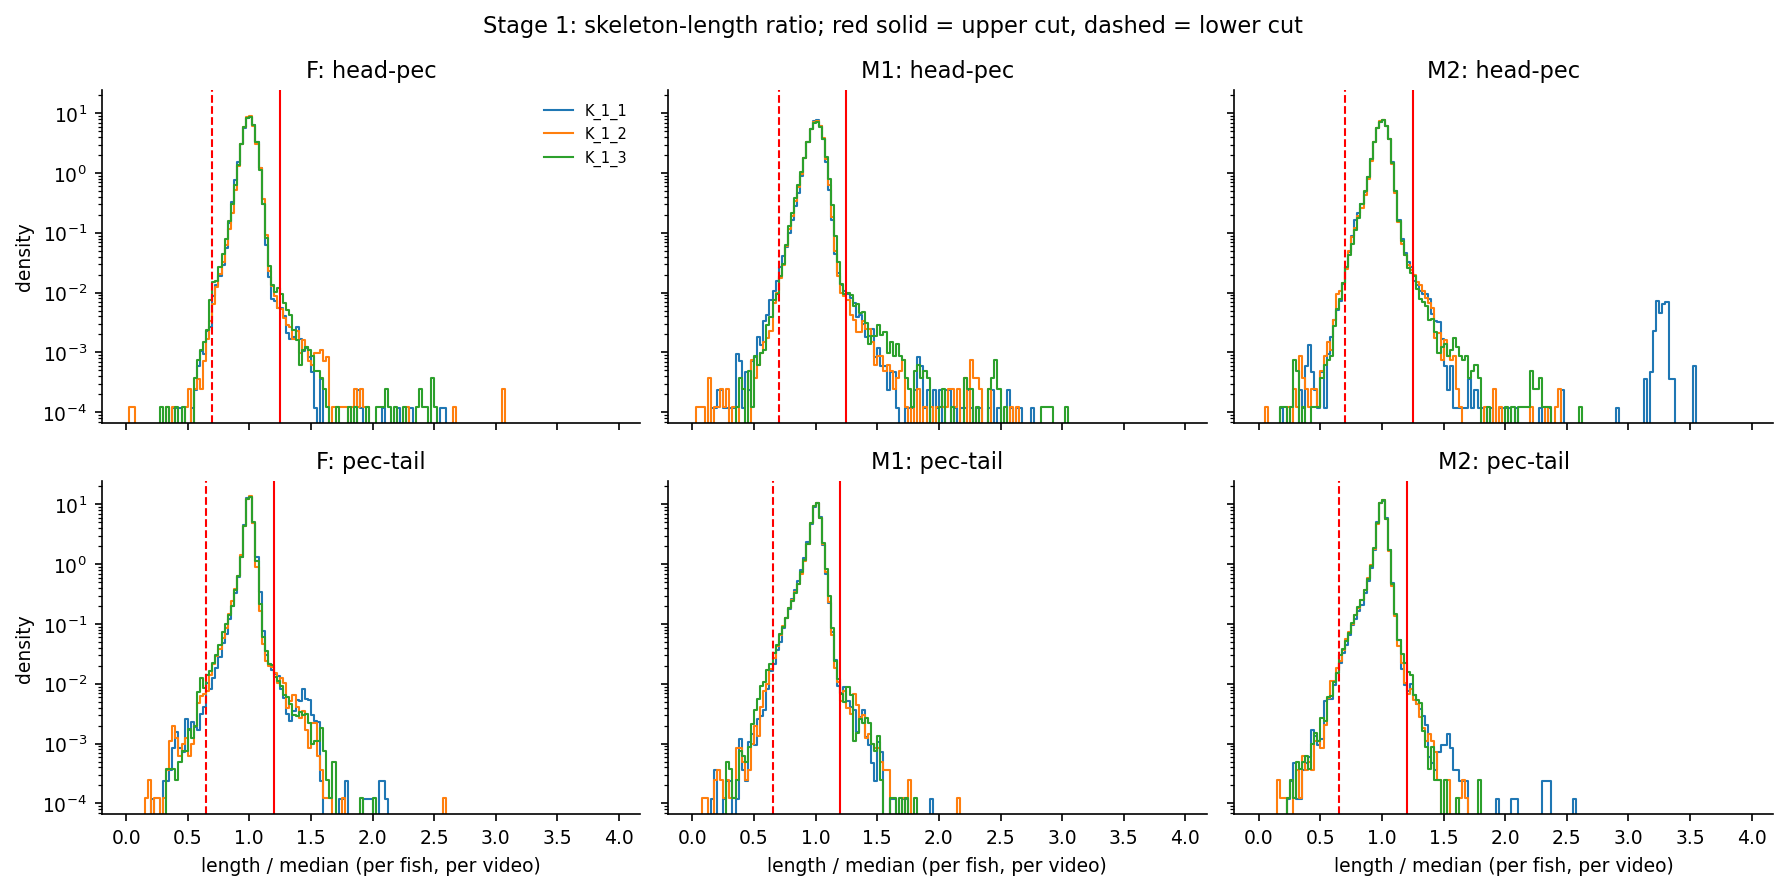

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S1_01_skeleton_length_histograms.png


In [3]:
K_LO_OVERRIDE = {}     # e.g. {"head_pec": 0.5}
K_HI_OVERRIDE = {}     # e.g. {"pec_tail": 1.6}
K_LO.update(K_LO_OVERRIDE); K_HI.update(K_HI_OVERRIDE)
print("used k_lo:", K_LO, " k_hi:", K_HI)

bins = np.linspace(0, 4, 161)
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for row, k in enumerate(RATIO):
    for col, fish in enumerate(M.NAMES):
        ax = axes[row, col]
        for e, r in RATIO[k].items():
            h, _ = np.histogram(r[:, col][np.isfinite(r[:, col])], bins=bins, density=True)
            ax.step(bins[:-1], h, where="post", lw=1, label=e[9:-5])
        ax.axvline(K_HI[k], color="r", lw=1); ax.axvline(K_LO[k], color="r", lw=1, ls="--")
        ax.set_yscale("log"); ax.set_title(f"{fish}: {k.replace('_', '-')}")
        if row == 1: ax.set_xlabel("length / median (per fish, per video)")
        if col == 0: ax.set_ylabel("density")
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle("Stage 1: skeleton-length ratio; red solid = upper cut, dashed = lower cut")
fig.tight_layout()
show(fig, 1, 1, "skeleton_length_histograms")

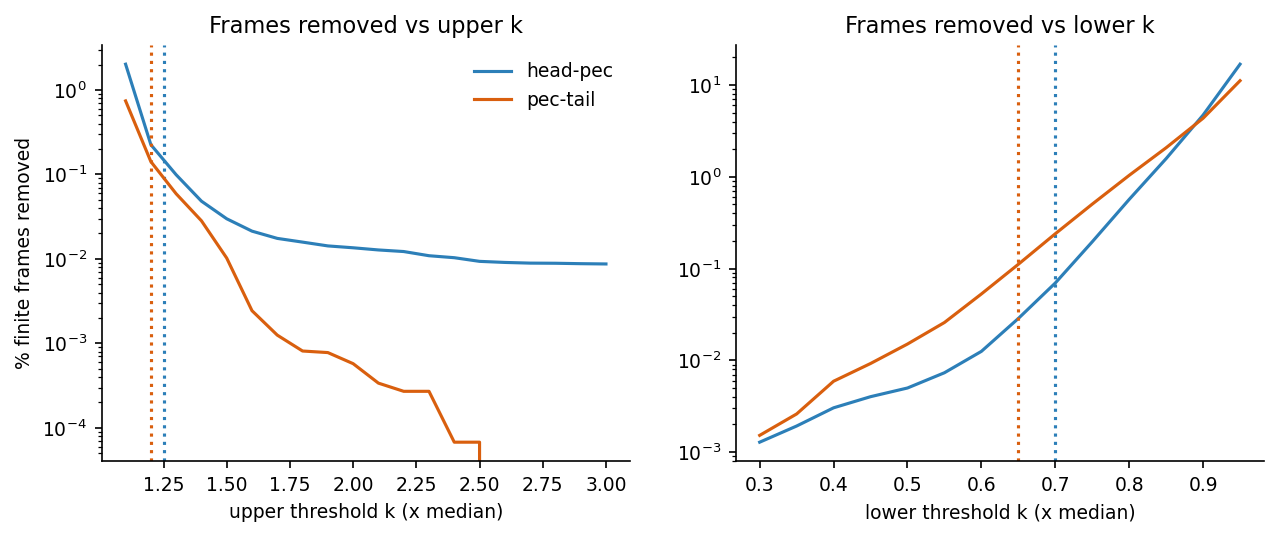

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S1_02_threshold_sweep_removed_fraction.png


In [4]:
ks_hi = np.arange(1.1, 3.01, 0.1); ks_lo = np.arange(0.3, 1.0, 0.05)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for k, c in (("head_pec", "#2c7fb8"), ("pec_tail", "#d95f0e")):
    pooled = np.concatenate([r.ravel() for r in RATIO[k].values()]); pooled = pooled[np.isfinite(pooled)]
    axes[0].plot(ks_hi, [100 * (pooled > x).mean() for x in ks_hi], color=c, label=k.replace("_", "-"))
    axes[0].axvline(K_HI[k], color=c, ls=":")
    axes[1].plot(ks_lo, [100 * (pooled < x).mean() for x in ks_lo], color=c, label=k.replace("_", "-"))
    axes[1].axvline(K_LO[k], color=c, ls=":")
axes[0].set_yscale("log"); axes[0].set_xlabel("upper threshold k (x median)"); axes[0].set_ylabel("% finite frames removed")
axes[1].set_yscale("log"); axes[1].set_xlabel("lower threshold k (x median)")
axes[0].legend(frameon=False); axes[0].set_title("Frames removed vs upper k"); axes[1].set_title("Frames removed vs lower k")
show(fig, 1, 2, "threshold_sweep_removed_fraction")

In [5]:
CLEAN, BAD, MED = {}, {}, {}
rows = []
for e, t in TR.items():
    CLEAN[e], BAD[e], MED[e] = M.clean_skeleton(t["named"], K_LO, K_HI)
    fin = np.isfinite(t["named"]).all(axis=(2, 3))
    for i, fish in enumerate(M.NAMES):
        rows.append({"experiment": e, "fish": fish, "finite_frames": int(fin[:, i].sum()),
                     "removed_frames": int(BAD[e][:, i].sum()),
                     "removed_pct": round(100 * BAD[e][:, i].sum() / max(fin[:, i].sum(), 1), 3),
                     "median_head_pec_mm": round(float(MED[e]["head_pec"][i]), 2),
                     "median_pec_tail_mm": round(float(MED[e]["pec_tail"][i]), 2)})
removal = pd.DataFrame(rows)
removal.to_csv(OUT / "S1_removal_table.csv", index=False)
removal

,experiment,fish,finite_frames,removed_frames,removed_pct,median_head_pec_mm,median_pec_tail_mm
0,20251225_K_1_1_FCMC,F,335742,1195,0.356,7.21,17.42
1,20251225_K_1_1_FCMC,M1,334673,1498,0.448,6.65,17.72
2,20251225_K_1_1_FCMC,M2,333445,2046,0.614,7.14,18.09
3,20251225_K_1_2_FCMC,F,326618,1201,0.368,7.27,17.50
4,20251225_K_1_2_FCMC,M1,326231,1263,0.387,6.62,17.82
5,20251225_K_1_2_FCMC,M2,326093,1797,0.551,7.11,18.20
6,20251225_K_1_3_FCMC,F,323064,1310,0.405,7.29,17.53
7,20251225_K_1_3_FCMC,M1,322889,1694,0.525,6.65,17.98
8,20251225_K_1_3_FCMC,M2,323078,1672,0.518,7.13,18.31


再抽被去掉的骨架画出来，肉眼确认确实是错的（上排 XY，下排 XZ，单位 mm；红线 = 被去掉的那条鱼，灰/蓝/橙 = F/M1/M2）。前三列是超上限，后三列是低于下限。

{'upper': 8582, 'lower': 5354}


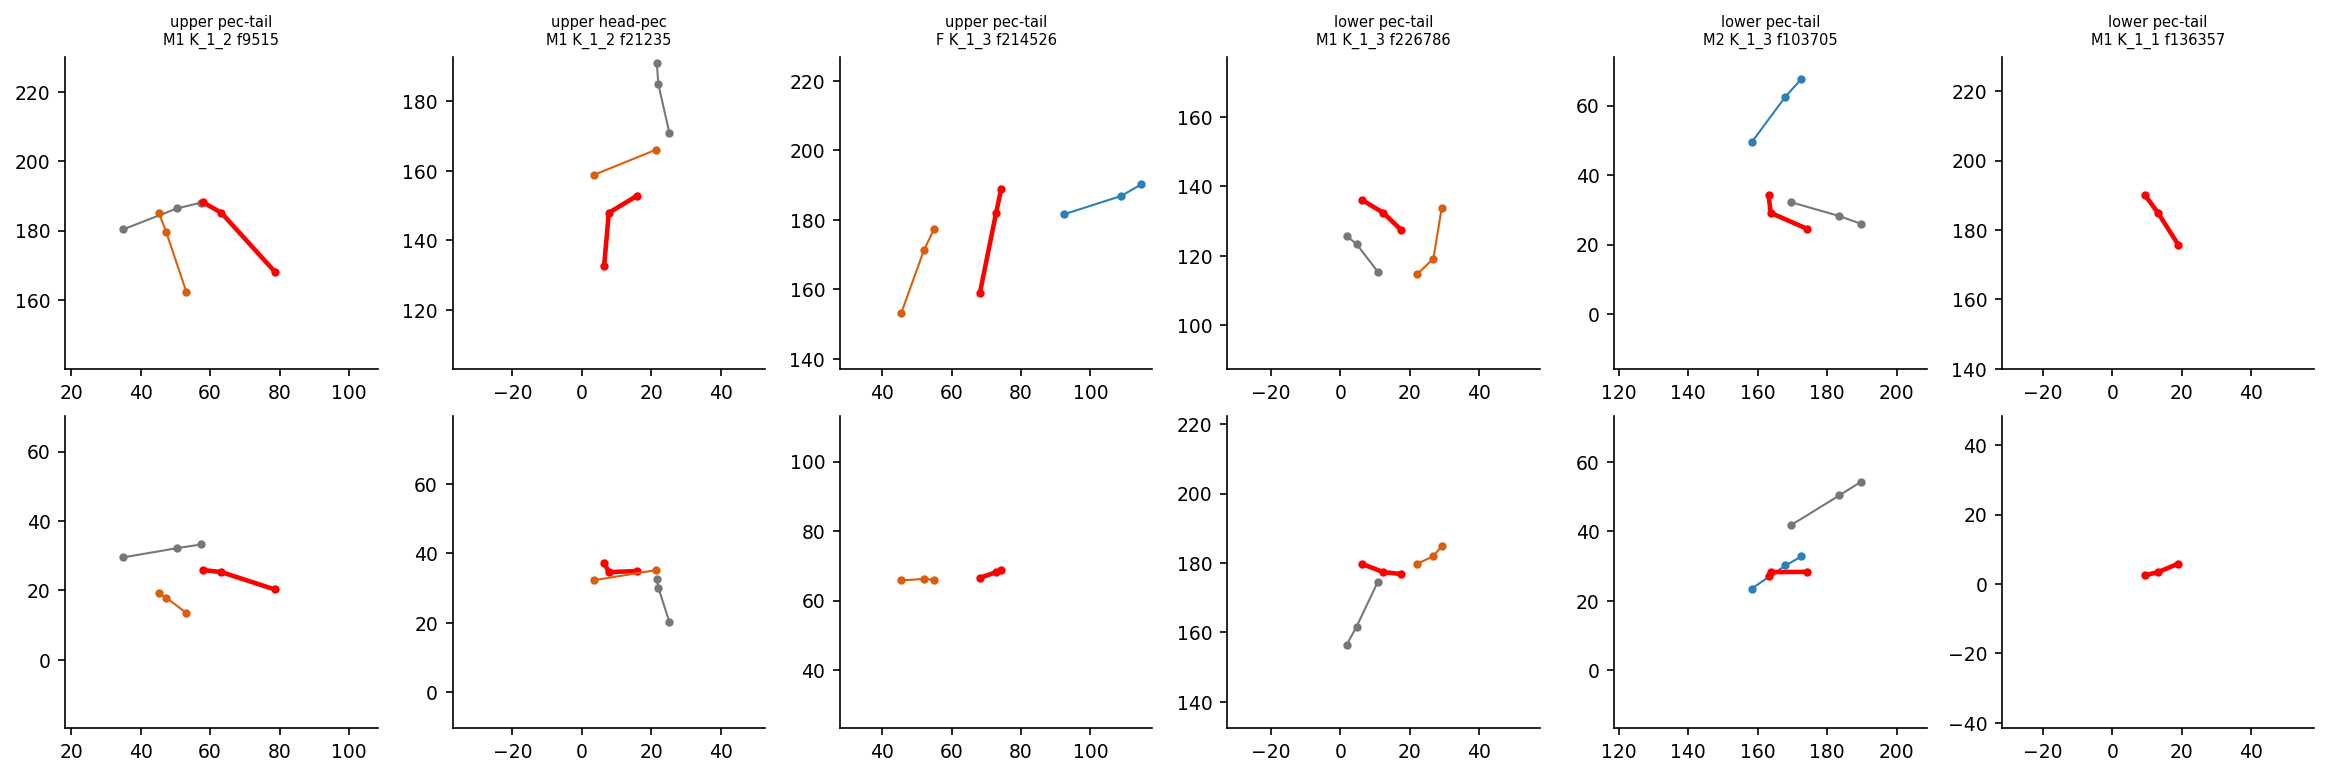

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S1_03_removed_skeleton_examples.png


In [6]:
rng = np.random.default_rng(1)
cands = {"upper": [], "lower": []}
for e, t in TR.items():
    L = M.skeleton_lengths(t["named"])
    for i in range(3):
        for k in ("head_pec", "pec_tail"):
            med = MED[e][k][i]
            for tag, mask in (("upper", L[k][:, i] > K_HI[k] * med), ("lower", L[k][:, i] < K_LO[k] * med)):
                for f in np.flatnonzero(mask & ~t["blocked"]):
                    cands[tag].append((e, int(f), i, k))
print({k: len(v) for k, v in cands.items()})
pick = []
for tag in ("upper", "lower"):
    if cands[tag]:
        idx = rng.choice(len(cands[tag]), min(3, len(cands[tag])), replace=False)
        pick += [(tag, *cands[tag][j]) for j in idx]
fig, axes = plt.subplots(2, max(len(pick), 1), figsize=(2.6 * max(len(pick), 1), 5.2), squeeze=False)
fish_col = ["#777777", "#2c7fb8", "#d95f0e"]
for col, (tag, e, f, i, k) in enumerate(pick):
    nodes = TR[e]["named"][f]
    centre = nodes[i, 1]
    for r, (a, b) in enumerate(((0, 1), (0, 2))):
        ax = axes[r, col]
        for j in range(3):
            xy = nodes[j][:, [a, b]]
            ax.plot(xy[:, 0], xy[:, 1], "-o", ms=3, color="r" if j == i else fish_col[j], lw=2.2 if j == i else 1)
        ax.set_xlim(centre[a] - 45, centre[a] + 45); ax.set_ylim(centre[b] - 45, centre[b] + 45); ax.set_aspect("equal")
        if r == 0: ax.set_title(f"{tag} {k.replace('_', '-')}\n{M.NAMES[i]} {e[9:-5]} f{TR[e]['frames'][f]}", fontsize=7)
fig.tight_layout()
show(fig, 1, 3, "removed_skeleton_examples")

In [7]:
M.update_params("stage1", {
    "k_lo": K_LO, "k_hi": K_HI, "rule": "frame removed if head-pec or pec-tail is outside [k_lo, k_hi] x per-(video, fish) median",
    "overrides": {"lo": K_LO_OVERRIDE, "hi": K_HI_OVERRIDE},
    "removed_pct_mean": float(removal["removed_pct"].mean())})
print(M.load_params()["stage1"])

{'k_lo': {'head_pec': 0.7000000000000001, 'pec_tail': 0.65}, 'k_hi': {'head_pec': 1.25, 'pec_tail': 1.2000000000000002}, 'rule': 'frame removed if head-pec or pec-tail is outside [k_lo, k_hi] x per-(video, fish) median', 'overrides': {'lo': {}, 'hi': {}}, 'removed_pct_mean': 0.4635555555555555}


## 阶段 2：插值（挖洞测试）

线性、只填 ≤ L 帧的缺口、每个空间维度分别做，**不跨过审阅判为不可用的片段**（`fill_gaps` 里被阻断的帧所在的缺口一律不填）。
L 的候选：3、5、8 帧。

挖洞测试：在已经连续有效的段里人为挖掉 g 帧（整条鱼骨架），用两端线性插值，和真值比较。
误差用**体长的比例**表示（嘴–尾中位数）。判据：p95 误差 ≤ `TOL_BL` 体长的**最大**候选 L。
`TOL_BL = 0.05` 是起点（约 1.2 mm），不是标准值；另画“快速段”（挖洞两端位移最大的 10%）的曲线，它比平均更严。
也画真实缺口的长度分布：L 取多大，实际能补上多少缺口。

natural gaps (not touching reviewed-out frames): 6901; median 2, p95 12, max 1475


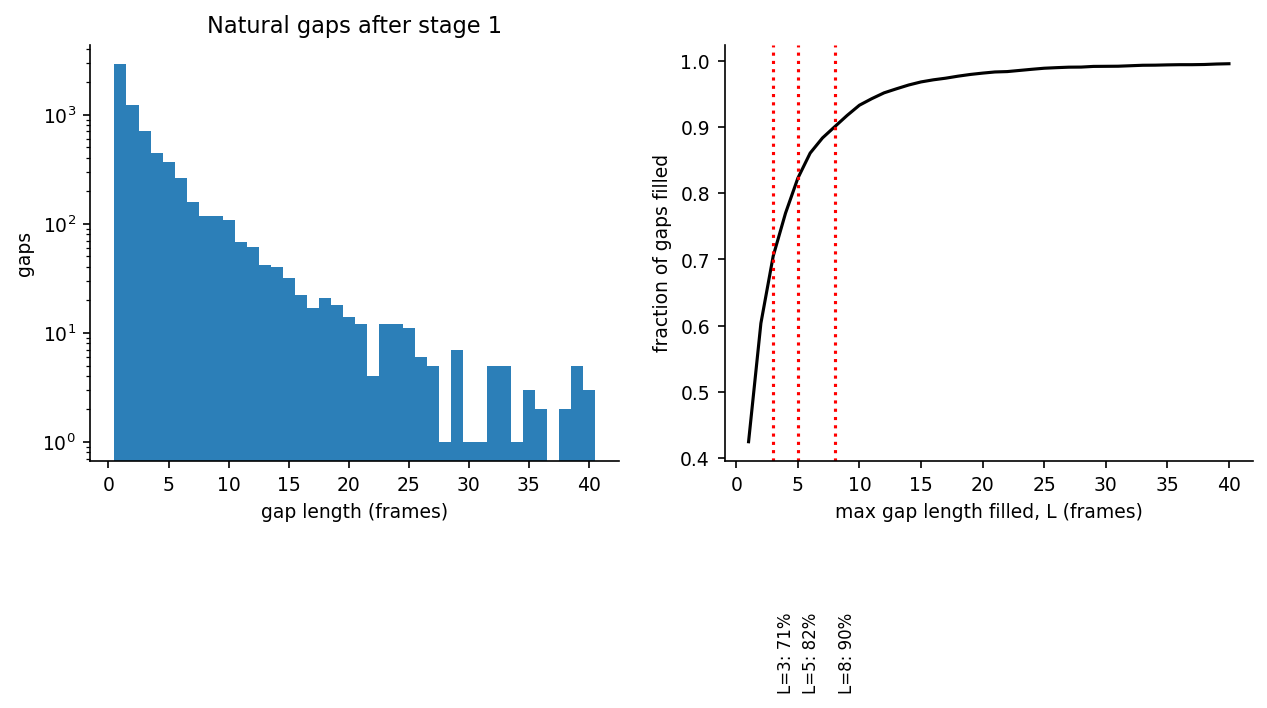

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S2_01_gap_length_distribution.png


In [8]:
TOL_BL = 0.05
CAND_L = (3, 5, 8)
GS = list(range(1, 13))
gaps = np.concatenate([M.gap_lengths(CLEAN[e], TR[e]["blocked"]) for e in DEV])
print(f"natural gaps (not touching reviewed-out frames): {len(gaps)}; median {np.median(gaps):.0f}, p95 {np.percentile(gaps, 95):.0f}, max {gaps.max()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(gaps[gaps <= 40], bins=np.arange(0.5, 41.5), color="#2c7fb8"); ax[0].set_yscale("log")
ax[0].set_xlabel("gap length (frames)"); ax[0].set_ylabel("gaps"); ax[0].set_title("Natural gaps after stage 1")
xs = np.arange(1, 41)
ax[1].plot(xs, [(gaps <= x).mean() for x in xs], color="k")
for L_ in CAND_L:
    ax[1].axvline(L_, ls=":", color="r"); ax[1].text(L_ + 0.3, 0.05, f"L={L_}: {(gaps <= L_).mean():.0%}", rotation=90, fontsize=8)
ax[1].set_xlabel("max gap length filled, L (frames)"); ax[1].set_ylabel("fraction of gaps filled")
show(fig, 2, 1, "gap_length_distribution")

 gap    p50    p95  p95_fast     n
   1 0.0057 0.0148    0.0302 13500
   2 0.0064 0.0172    0.0292 13500
   3 0.0068 0.0201    0.0363 13500
   4 0.0076 0.0244    0.0433 13500
   5 0.0084 0.0290    0.0514 13500
   6 0.0089 0.0327    0.0557 13500
   7 0.0100 0.0376    0.0666 13500
   8 0.0109 0.0430    0.0725 13500
   9 0.0120 0.0467    0.0775 13500
  10 0.0130 0.0499    0.0762 13500
  11 0.0142 0.0527    0.0819 13500
  12 0.0152 0.0561    0.0976 13500
candidates meeting p95 <= TOL_BL: [3, 5, 8] -> FILL_LIMIT = 8


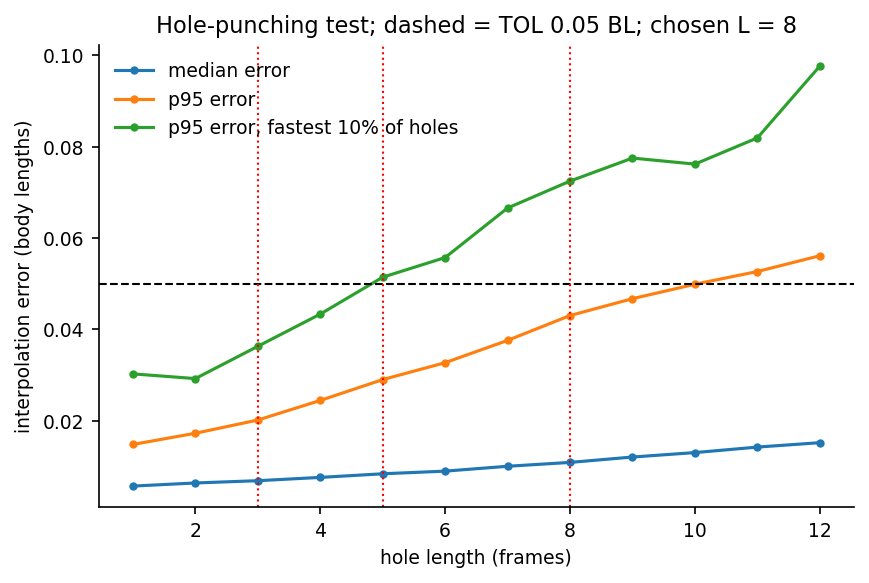

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S2_02_hole_punch_interpolation_error.png


{'stage0': {'split_seed': 20261106,
  'dev_groups': ['K_1'],
  'test_groups': ['P_1'],
  'n_groups_dev': 1,
  'acceleration_quantile': 0.999,
  'acceleration_threshold_mm_s2': 237186.70347709933,
  'n_swaps': 64,
  'swap_median_nearest_pair_BL': 0.30888883375700166,
  'random_window_median_nearest_pair_BL': 0.8999210723674602,
  'accel_swap_hit_rate': 0.8594771241830066,
  'accel_chance_rate': 0.14311069403455015,
  'calibration': 'no per-video record; thresholds are per (video, fish)'},
 'stage1': {'k_lo': {'head_pec': 0.7000000000000001, 'pec_tail': 0.65},
  'k_hi': {'head_pec': 1.25, 'pec_tail': 1.2000000000000002},
  'rule': 'frame removed if head-pec or pec-tail is outside [k_lo, k_hi] x per-(video, fish) median',
  'overrides': {'lo': {}, 'hi': {}},
  'removed_pct_mean': 0.4635555555555555},
 'stage2': {'fill_limit': 8,
  'candidates': [3, 5, 8],
  'tol_bl': 0.05,
  'rule': 'largest candidate L with p95 hole error <= tol_bl',
  'table': [{'gap': 1,
    'p50': 0.00567,
    'p95': 

In [9]:
rng = np.random.default_rng(2)
PUNCH = {g: {"err": [], "disp": []} for g in GS}
for e in DEV:
    x, blocked = CLEAN[e], TR[e]["blocked"]
    bl = np.nanmedian(M.skeleton_lengths(TR[e]["named"])["head_tail"], axis=0)
    okall = np.isfinite(x).all(axis=(2, 3))
    for f in range(3):
        ok = okall[:, f] & ~blocked
        c = np.concatenate([[0], np.cumsum(ok)])
        for g in GS:
            s = np.arange(1, len(ok) - g - 1)
            cand = s[(c[s + g + 1] - c[s - 1]) == g + 2]
            if len(cand) == 0:
                continue
            pick = rng.choice(cand, min(1500, len(cand)), replace=False)
            a, b = x[pick - 1, f], x[pick + g, f]
            errs = []
            for kk in range(g):
                est = a + (kk + 1) / (g + 1) * (b - a)
                errs.append(np.linalg.norm(est - x[pick + kk, f], axis=-1))
            err = np.stack(errs, 1).reshape(len(pick), -1).mean(1) / bl[f]
            PUNCH[g]["err"].append(err)
            PUNCH[g]["disp"].append(np.linalg.norm(b[:, 1] - a[:, 1], axis=-1) / bl[f])
curve = []
for g in GS:
    err, disp = np.concatenate(PUNCH[g]["err"]), np.concatenate(PUNCH[g]["disp"])
    fast = disp >= np.quantile(disp, 0.9)
    curve.append({"gap": g, "p50": np.median(err), "p95": np.percentile(err, 95), "p95_fast": np.percentile(err[fast], 95), "n": len(err)})
curve = pd.DataFrame(curve)
curve.to_csv(OUT / "S2_hole_punch_error.csv", index=False)
ok_L = [L_ for L_ in CAND_L if curve.loc[curve["gap"] == L_, "p95"].iloc[0] <= TOL_BL]
FILL_LIMIT = max(ok_L) if ok_L else min(CAND_L)
print(curve.round(4).to_string(index=False))
print("candidates meeting p95 <= TOL_BL:", ok_L, "-> FILL_LIMIT =", FILL_LIMIT)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(curve["gap"], curve["p50"], "-o", ms=3, label="median error")
ax.plot(curve["gap"], curve["p95"], "-o", ms=3, label="p95 error")
ax.plot(curve["gap"], curve["p95_fast"], "-o", ms=3, label="p95 error, fastest 10% of holes")
ax.axhline(TOL_BL, color="k", ls="--", lw=1)
for L_ in CAND_L: ax.axvline(L_, color="r", ls=":", lw=1)
ax.set_xlabel("hole length (frames)"); ax.set_ylabel("interpolation error (body lengths)")
ax.set_title(f"Hole-punching test; dashed = TOL {TOL_BL} BL; chosen L = {FILL_LIMIT}")
ax.legend(frameon=False)
show(fig, 2, 2, "hole_punch_interpolation_error")
M.update_params("stage2", {"fill_limit": int(FILL_LIMIT), "candidates": list(CAND_L), "tol_bl": TOL_BL,
                           "rule": "largest candidate L with p95 hole error <= tol_bl", "table": curve.round(5).to_dict("records")})

## 阶段 3：平滑（Savitzky–Golay，二阶）

候选窗口 5、7、9、11 帧（0.030–0.066 s）。只在插值之后、连续片段内部做，片段两端各丢半个窗口。判据（只在开发组）：

* (a) **静止时的抖动**：静止帧 = 该鱼胸鳍点速度（用 31 帧重平滑算）最低的 25%；抖动 = 这些帧上关键点二阶差分的 RMS。看相对未平滑的比值。
* (b) **速度峰保留**：BORIS 里的行为段（只用开发组、用来**定位快行为**，不调阈值）：actor 胸鳍点在段内（前后各 17 帧）的最大速度，窗口 w 相对 w=5 的比值。
  未平滑的速度峰含噪声会偏高，所以以 w=5 为参照，同时画相对未平滑的版本。

取噪声明显下降、峰值保留 ≥ `RETAIN_MIN` 的**最大**窗口。`RETAIN_MIN = 0.90` 是起点。短行为（≤ 12 帧）单独看。

In [10]:
CAND_W = (5, 7, 9, 11)
PAD = 17
RETAIN_MIN = 0.90
FILLED_NAN = {}
jit_rows, peak_rows, best = [], [], {"peak": 0}
loss_rows = []
for e in DEV:
    t = TR[e]
    filled = M.fill_gaps(CLEAN[e], FILL_LIMIT, t["blocked"])
    var = {1: filled}
    for w in CAND_W:
        var[w] = M.smooth_sg(filled, w)
    heavy = M.smooth_sg(filled, 31)
    speed_h = np.linalg.norm(np.diff(heavy[:, :, M.PECT], axis=0), axis=-1) * t["fps"]       # (T-1, 3)
    fin = {w: np.isfinite(v).all(axis=(2, 3)) for w, v in var.items()}
    common = np.logical_and.reduce(list(fin.values()) + [np.isfinite(heavy).all(axis=(2, 3))])
    for w in var:
        loss_rows.append({"experiment": e, "w": w, "finite_pct": 100 * fin[w].mean()})
    for f in range(3):
        sp = np.concatenate([speed_h[:, f], [np.nan]])
        thr = np.nanquantile(sp[common[:, f]], 0.25)
        still = common[:, f] & (sp <= thr)
        for w, v in var.items():
            d2 = v[2:, f] - 2 * v[1:-1, f] + v[:-2, f]
            m = still[1:-1] & still[:-2] & still[2:]
            jit_rows.append({"experiment": e, "fish": M.NAMES[f], "w": w, "rms": float(np.sqrt(np.nanmean(d2[m] ** 2))), "n": int(m.sum())})
    bouts = M.bouts_of(e)
    off = int(t["frames"][0])
    for r in bouts.itertuples():
        who = str(r.who)
        if "->" not in who:
            continue
        actor = who.split("->")[0]
        if actor not in M.NAMES:
            continue
        a, b = int(r.start) - off - PAD, int(r.end) - off + PAD + 1
        if a < 1 or b >= len(filled):
            continue
        i = M.NAMES.index(actor)
        peaks = {}
        for w, v in var.items():
            sp = np.linalg.norm(np.diff(v[a:b, i, M.PECT], axis=0), axis=-1) * t["fps"]
            peaks[w] = np.nanmax(sp) if np.isfinite(sp).mean() > 0.8 else np.nan
        if all(np.isfinite(list(peaks.values()))):
            dur = int(r.end - r.start + 1)
            peak_rows.append({"experiment": e, "behavior": M.canonical_behavior(r.behavior), "who": who, "dur": dur, **{f"p{w}": peaks[w] for w in var}})
            if peaks[1] > best["peak"] and dur > 3:
                best = {"peak": peaks[1], "exp": e, "who": who, "behavior": r.behavior, "a": a, "b": b, "i": i,
                        "speeds": {w: np.linalg.norm(np.diff(v[a:b, i, M.PECT], axis=0), axis=-1) * t["fps"] for w, v in var.items()}}
    del var, heavy
jit = pd.DataFrame(jit_rows); peaks = pd.DataFrame(peak_rows); loss = pd.DataFrame(loss_rows)
print("bouts with a usable peak:", len(peaks)); print(peaks["behavior"].value_counts().to_string())
print("finite-frame share after smoothing (%):"); print(loss.groupby("w")["finite_pct"].mean().round(2).to_string())

bouts with a usable peak: 196
behavior
qc          136
att          35
chase        14
display       6
approach      2
touch         2
wrap          1
finite-frame share after smoothing (%):
w
1     94.13
5     94.02
7     93.97
9     93.92
11    93.87


    median_all  p25_all  median_short  jitter_ratio
5        1.000    1.000         1.000         0.419
7        0.912    0.800         0.924         0.264
9        0.864    0.727         0.900         0.196
11       0.832    0.685         0.908         0.155
windows keeping the peak >= 0.9 : [5, 7] -> WINDOW = 7 (0.042 s at 166 fps)


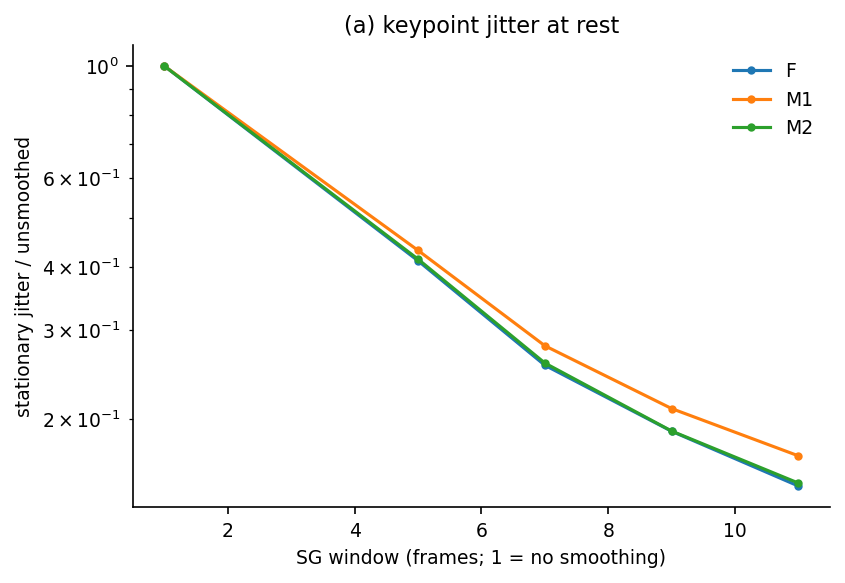

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S3_01_stationary_jitter_vs_window.png


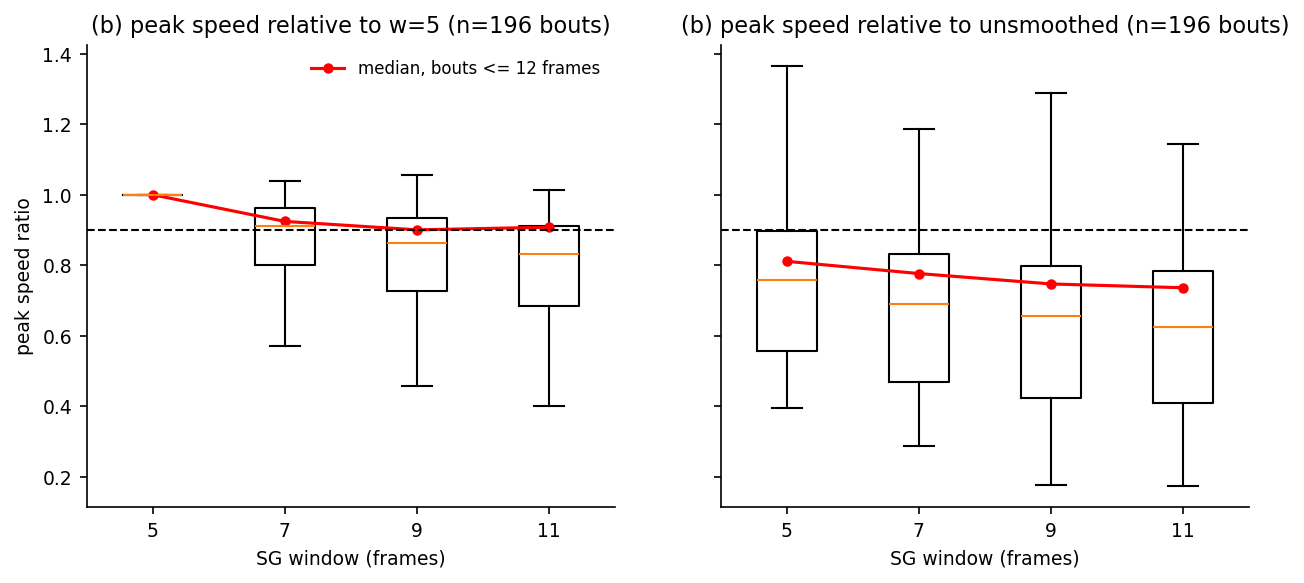

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S3_02_peak_speed_retention_vs_window.png


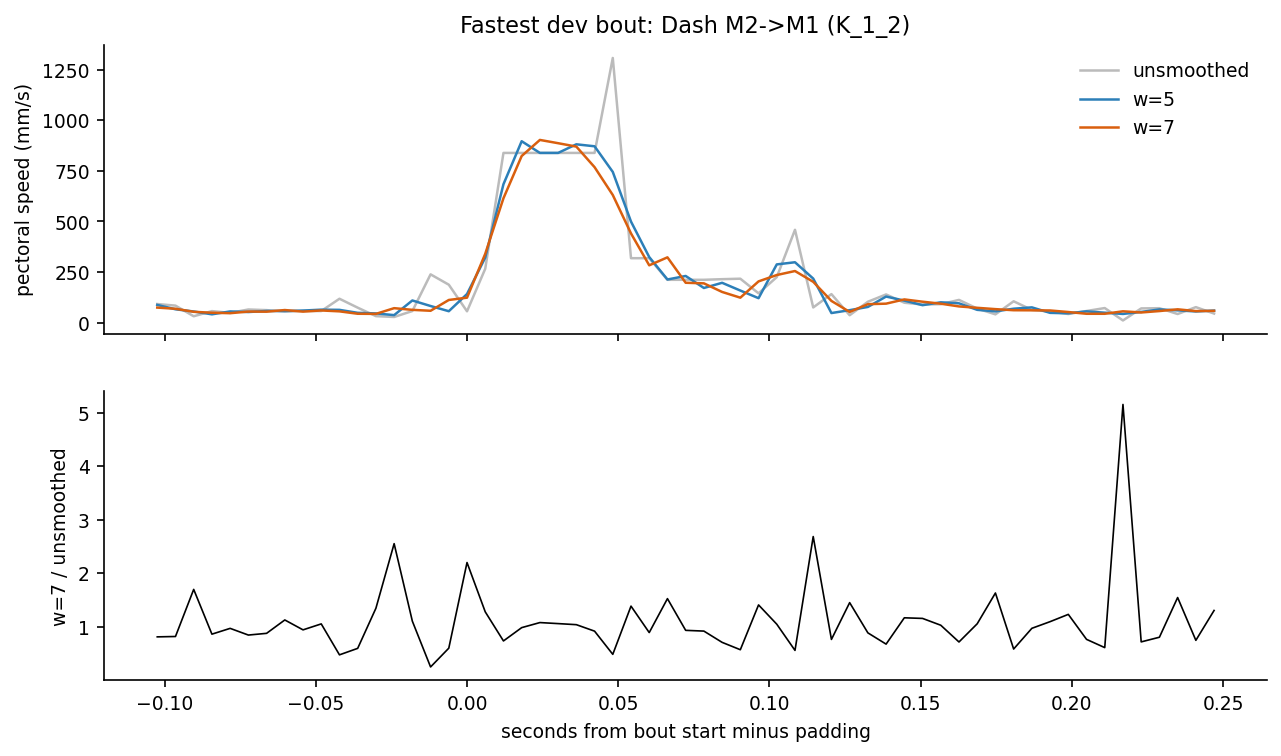

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S3_03_fastest_bout_example.png
{'window': 7, 'order': 2, 'candidates': [5, 7, 9, 11], 'retain_min': 0.9, 'rule': 'largest window whose median peak-speed ratio vs w=5 >= retain_min (all bouts and bouts <= 12 frames)', 'table': [{'index': 5, 'median_all': 1.0, 'p25_all': 1.0, 'median_short': 1.0, 'jitter_ratio': 0.4192}, {'index': 7, 'median_all': 0.9119, 'p25_all': 0.7998, 'median_short': 0.9243, 'jitter_ratio': 0.2643}, {'index': 9, 'median_all': 0.8641, 'p25_all': 0.7274, 'median_short': 0.9004, 'jitter_ratio': 0.1961}, {'index': 11, 'median_all': 0.8319, 'p25_all': 0.6848, 'median_short': 0.9078, 'jitter_ratio': 0.1552}]}


In [11]:
jit_mean = jit.groupby(["fish", "w"])["rms"].mean().unstack("w")
jit_ratio = jit_mean.div(jit_mean[1], axis=0)
for w in CAND_W:
    peaks[f"ret{w}"] = peaks[f"p{w}"] / peaks["p5"]
    peaks[f"retraw{w}"] = peaks[f"p{w}"] / peaks["p1"]
short = peaks["dur"] <= 12
ret = pd.DataFrame({"median_all": [peaks[f"ret{w}"].median() for w in CAND_W],
                    "p25_all": [peaks[f"ret{w}"].quantile(0.25) for w in CAND_W],
                    "median_short": [peaks.loc[short, f"ret{w}"].median() for w in CAND_W],
                    "jitter_ratio": [jit_ratio[w].mean() for w in CAND_W]}, index=CAND_W)
print(ret.round(3).to_string())
ok_w = [w for w in CAND_W if ret.loc[w, "median_all"] >= RETAIN_MIN and (np.isnan(ret.loc[w, "median_short"]) or ret.loc[w, "median_short"] >= RETAIN_MIN)]
WINDOW = max(ok_w) if ok_w else min(CAND_W)
print("windows keeping the peak >=", RETAIN_MIN, ":", ok_w, "-> WINDOW =", WINDOW, f"({WINDOW / 166:.3f} s at 166 fps)")
ret.round(4).to_csv(OUT / "S3_window_selection.csv")

fig, ax = plt.subplots(figsize=(6, 4))
for f in M.NAMES:
    ax.plot([1] + list(CAND_W), jit_ratio.loc[f, [1] + list(CAND_W)], "-o", ms=3, label=f)
ax.set_xlabel("SG window (frames; 1 = no smoothing)"); ax.set_ylabel("stationary jitter / unsmoothed")
ax.set_yscale("log"); ax.set_title("(a) keypoint jitter at rest"); ax.legend(frameon=False)
show(fig, 3, 1, "stationary_jitter_vs_window")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col, title in ((axes[0], "ret", "relative to w=5"), (axes[1], "retraw", "relative to unsmoothed")):
    data = [peaks[f"{col}{w}"].dropna() for w in CAND_W]
    ax.boxplot(data, tick_labels=[str(w) for w in CAND_W], showfliers=False)
    ax.plot(range(1, len(CAND_W) + 1), [peaks.loc[short, f"{col}{w}"].median() for w in CAND_W], "r-o", ms=4, label="median, bouts <= 12 frames")
    ax.axhline(RETAIN_MIN, color="k", ls="--", lw=1); ax.set_xlabel("SG window (frames)"); ax.set_title(f"(b) peak speed {title} (n={len(peaks)} bouts)")
axes[0].set_ylabel("peak speed ratio"); axes[0].legend(frameon=False, fontsize=8)
show(fig, 3, 2, "peak_speed_retention_vs_window")

fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
if best["peak"] > 0:
    sp = best["speeds"]; tt = (np.arange(len(sp[1])) - PAD) / 166
    for w, c in ((1, "#bbbbbb"), (5, "#2c7fb8"), (WINDOW, "#d95f0e")):
        ax[0].plot(tt, sp[w], color=c, lw=1.2, label="unsmoothed" if w == 1 else f"w={w}")
    ax[0].set_ylabel("pectoral speed (mm/s)"); ax[0].legend(frameon=False)
    ax[0].set_title(f"Fastest dev bout: {best['behavior']} {best['who']} ({best['exp'][9:-5]})")
    ax[1].plot(tt, np.nan_to_num(sp[WINDOW]) / np.maximum(np.nan_to_num(sp[1]), 1e-9), color="k", lw=0.8)
    ax[1].set_ylabel(f"w={WINDOW} / unsmoothed"); ax[1].set_xlabel("seconds from bout start minus padding")
show(fig, 3, 3, "fastest_bout_example")
M.update_params("stage3", {"window": int(WINDOW), "order": 2, "candidates": list(CAND_W), "retain_min": RETAIN_MIN,
                           "rule": "largest window whose median peak-speed ratio vs w=5 >= retain_min (all bouts and bouts <= 12 frames)",
                           "table": ret.round(4).reset_index().to_dict("records")})
print(M.load_params()["stage3"])